# 02 · Synthetic households (v3)

This notebook creates the **rows** of the matrix: 5,000 simulated households, and for each one

1. its **household facts** (smart devices and which device classes they are, household size, age band, children),
2. its **decision on every item** from notebook 01, drawn from a model whose numbers come from published studies,
3. its **answers to the candidate onboarding questions**: realistic, concrete situations with examples, read from its own decisions.

Later notebooks cluster the decisions (→ presets) and learn which answers predict the cluster (→ onboarding tree).

> **This is not survey data.** v3 takes its effects from the studies below, translated into PPD core terms through
> `references/crosswalk.csv`. Every number carries a grade (A: smart-home study, exact term match · B: looser match
> or a non-home level · C: other domain · D: our assumption). The plan is in the capstone's
> `docs/household-presets-remodelling-plan.md`.

| Short | Study | What it gives v3 |
| --- | --- | --- |
| A18 | Apthorpe et al. 2018, *Discovering Smart Home IoT Privacy Norms Using Contextual Integrity*, IMWUT | handling context, purposes, data types, device fit, retention (smart-home flows, 1,731 people) |
| N17 | Emami-Naeini et al. 2017, *Privacy Expectations and Preferences in an IoT World*, SOUPS | data types at home, benefit to the person, targets (1,007 people) |
| Z21 | Zhang et al. 2021, *"Did you know this camera tracks your mood?"*, PoPETs | purposes, retention (video analytics, 123 people) |
| S20 | Smullen, Feng, Zhang, Sadeh 2020, *The Best of Both Worlds*, PoPETs | which background facts matter; purpose varies most for ads |
| L16 | Liu et al. 2016, *Follow My Recommendations*, SOUPS | answers come from the person's own aggregated choices |

### What changed from v2, and why

| v2 | v3 | Reason |
| --- | --- | --- |
| A hand-built score; every size chosen by us | The mixed-effects logistic model the studies fit; sizes from the studies, pooled per PPD term | Traceable numbers; the studies' coefficients plug in |
| Data type and purpose added separately; their combination only random cell noise | A household effect per data type × purpose, and device-class fit cells | N17: combinations of factors explain most |
| Households differ mostly by purpose | Household effects on purpose, data type and handling context | A18, N17: data type and recipient vary too |
| One sensitivity per factor level; data type × purpose only as noise | A data type × purpose fit table, and **shared concern patterns** over data type × purpose | Week 9 (Daniel): sensitivity depends on the data type *for* a purpose; Liu/Lin profiles differ by which permissions people grant |
| No device dimension | Each household owns device classes; owning one makes its fit cells more accepted | A18 §4.3, §5.7 |
| Decisions thresholded at `u ≥ 0` | Decisions drawn (logistic noise, shared within a cell and across handling contexts) | Real people are inconsistent; N17: majority baseline ≈ 50% |
| Strong retention trait; 17% *allow if* | Small condition effects | A18, Z21, N17: retention and anonymity are the weakest factors |
| Concern scaled every risk | Concern has a small effect | S20: privacy-concern scales were not predictive |
| Abstract questions answered from the same traits as the decisions | One concrete situation per cell (with examples), answered from the household's own decisions in that cell | S20, L16 asked about specific settings; removes the circularity |

In [1]:
import hashlib, json
from datetime import date
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit, logit

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, REF = ROOT / "data", ROOT / "references"
items = pd.read_csv(DATA / "items.csv")                              # from notebook 01
classes = pd.read_csv(DATA / "corpus" / "device_classes.csv")       # from notebook 01, §6
fit_cells = pd.read_csv(DATA / "corpus" / "device_fit.csv")
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
DATA_TYPES = ["ppd:identifierData", "ppd:profileData", "ppd:sensorData", "ppd:contentData", "ppd:locationData", "ppd:deviceAndNetworkData", "ppd:usageData"]
PURPOSES = ["ppd:coreFunctionality", "ppd:personalization", "ppd:communicationsAndNotifications", "ppd:security", "ppd:diagnosticsAndMaintenance", "ppd:analyticsAndImprovement", "ppd:legalCompliance", "ppd:advertisingAndMarketing"]
ACTIONS = ["ppd:collection", "ppd:use", "ppd:transfer", "ppd:inference"]
SOURCES = ["ppd:userProvided", "ppd:participantObserved", "ppd:participantGenerated", "ppd:householdProvided", "ppd:vendorProvided", "ppd:thirdPartyProvided", "ppd:derivedFromPriorData"]
HANDLING_CONTEXTS = ["ppd:householdContext", "ppd:vendorContext", "ppd:thirdPartyContext", "ppd:publicAudience"]
CLASSES = list(classes.device_class)
HOME, VENDOR, ADS, CORE, LOCATION = "ppd:householdContext", "ppd:vendorContext", "ppd:advertisingAndMarketing", "ppd:coreFunctionality", "ppd:locationData"
short = lambda term: term.split(":", 1)[1]
print(f"{len(items):,} items, {len(CLASSES)} device classes, {len(fit_cells)} fit cells loaded")

6,272 items, 7 device classes, 52 fit cells loaded


## Cells: data type × purpose × handling context

A **cell** groups the items that share data type, purpose and handling context (they differ only in action and
source): 7 × 8 × 4 = **224 cells** of 28 items each. The generator draws part of each household's noise per cell,
device fit is defined per cell, and the clustering notebook clusters households on their 224 cell averages, the way
S20 aggregated by app category × permission × purpose.

In [2]:
items["cell_id"] = (items.data_type.map(DATA_TYPES.index) * len(PURPOSES) + items.purpose.map(PURPOSES.index)) * len(HANDLING_CONTEXTS) + items.handling_context.map(HANDLING_CONTEXTS.index)
items["combo_id"] = items.groupby(["data_type", "purpose", "action", "source"], sort=False).ngroup()   # the same flow, any handling context
cells = items.groupby("cell_id").agg(data_type=("data_type", "first"), purpose=("purpose", "first"),
                                     handling_context=("handling_context", "first"), items=("item_id", "size"),
                                     real_items=("in_corpus", "sum")).reset_index()
N_CELLS, N_COMBOS = len(cells), items.combo_id.nunique()
print(f"{N_CELLS} cells of {cells['items'].iloc[0]} items; {N_COMBOS:,} flows that differ only in handling context")

224 cells of 28 items; 1,568 flows that differ only in handling context


## Part A · Evidence → parameters

The studies use their own vocabularies (Apthorpe's recipients and "transmission principles", Zhang's 16 video
purposes, Naeini's sensors). Each study term is first mapped onto the PPD core terms in
`references/crosswalk.csv`, with the kind of match (`exact`, `narrower`, `broader`, `partial`, `none`); rows marked
`used = no` never become effects. Then, per PPD field:

1. take each study's effects on the **log-odds of allowing**, as a difference from one baseline term the studies
   share (only differences travel between studies, not absolute rates);
2. average the study levels that map to the same PPD term, within the study;
3. average the studies (each study counts once);
4. grade the result by its best source (A–D, above).

**Apthorpe's scale.** Apthorpe reports average acceptability on −2…+2, not allow/deny. A difference of one point is
converted to `KAPPA = 1.4` on the log-odds scale: with respondents spread about 1.2 points around a flow's average, the
probability of rating it acceptable moves like a probit with slope 1/1.2, and a probit is 1.7× a logit
(1.7 / 1.2 ≈ 1.4). Grade C (a conversion, not a measurement); varied in sensitivity runs.

In [3]:
KAPPA = 1.4
cross = pd.read_csv(REF / "crosswalk.csv", dtype=str, keep_default_na=False)   # "null" is a level name, not missing
ap_tp = pd.read_csv(REF / "extracted" / "apthorpe2018_recipient_tp.csv", keep_default_na=False)
ap_sa = pd.read_csv(REF / "extracted" / "apthorpe2018_sender_attribute.csv")
naeini = pd.read_csv(REF / "extracted" / "naeini2017_allow_deny.csv")
zhang = pd.read_csv(REF / "extracted" / "zhang2021_allow_deny.csv")
targets = pd.read_csv(REF / "extracted" / "targets.csv").set_index("target")

DOMAIN = {"apthorpe2018": "home", "naeini2017": "home", "zhang2021": "other"}
def grade(study, relation):
    return "C" if DOMAIN[study] != "home" else ("A" if relation == "exact" else "B")

best = lambda relations: min(relations, key=lambda r: r != "exact")   # the closest match among several levels

def mapped(study, factor):
    """The crosswalk rows of one study factor, indexed by level."""
    return cross[(cross.study == study) & (cross.factor == factor)].set_index("level")

EVIDENCE = []   # one row per (PPD term, study): the study's contrast on the log-odds of allowing
def add(field, term, study, value, relation, levels, baseline):
    EVIDENCE.append({"field": field, "term": term, "study": study, "value": float(value),
                     "grade": grade(study, relation), "levels": ", ".join(levels), "baseline": baseline})
print(f"crosswalk: {len(cross)} study terms; used as effects: {(cross.used == 'yes').sum()}")
cross.groupby(["study", "relation"]).size().unstack(fill_value=0)

crosswalk: 65 study terms; used as effects: 36


relation,broader,exact,narrower,none,partial
study,,,,,
apthorpe2018,0,13,5,15,5
naeini2017,0,4,0,2,3
zhang2021,1,1,11,0,5


### A1 · Handling context (where a "recipient" goes)

PPD has no recipient field. For a transfer, `handling_context` *is* the recipient-side context (taxonomy-05 §6.6),
so Apthorpe's recipients map onto it, read together with `action = transfer`: every Apthorpe flow is a device sending
information. A named company is a role, not a term (§6.6): "its manufacturer" is `vendorContext`. The "null"
condition (no purpose given) is used, so purposes do not mix in. Baseline: `householdContext` (family and other
devices in the home).

In [4]:
m = mapped("apthorpe2018", "recipient")
null = ap_tp[ap_tp.transmission_principle == "null"].assign(term=lambda d: d.recipient.map(m.ppd_terms))
per_term = null.groupby("term").score.mean()
for term, levels in null.groupby("term").recipient:
    if term != HOME:
        add("handling_context", term, "apthorpe2018", (per_term[term] - per_term[HOME]) * KAPPA, best(m.loc[levels, "relation"]), levels, "householdContext")
pd.DataFrame(EVIDENCE).query("field == 'handling_context'")

,field,term,study,value,grade,levels,baseline
0,handling_context,ppd:publicAudience,apthorpe2018,-1.5680,B,social_media,householdContext
1,handling_context,ppd:thirdPartyContext,apthorpe2018,-1.7255,B,"doctor, police, isp, intelligence",householdContext
2,handling_context,ppd:vendorContext,apthorpe2018,-1.4420,A,manufacturer,householdContext


### A2 · Purposes

Baseline: advertising, the one purpose all three studies measure.

- **A18:** each purpose against "used for advertising" within the same recipient column, where both were asked.
- **Z21:** the log-odds of *deny* against generic surveillance (Table 6), sign flipped; its four ad purposes and the
  line-skipping offers pool into `advertisingAndMarketing`. Face-as-ID and attendance in public venues are not home
  core functionality, and the work/health predictions have no PPD purpose (crosswalk, `used = no`).
- **N17:** "not beneficial" against "beneficial" to the person (Table 7), read as advertising against core
  functionality (`partial`).

In [5]:
tbl = ap_tp.pivot(index="transmission_principle", columns="recipient", values="score")
m = mapped("apthorpe2018", "transmission_principle")
for level, r in m[(m.ppd_field == "purpose") & (m.used == "yes") & (m.ppd_terms != ADS)].iterrows():
    diff = (tbl.loc[level] - tbl.loc["advertising"]).dropna()
    add("purpose", r.ppd_terms, "apthorpe2018", diff.mean() * KAPPA, r.relation, [level], f"advertising ({len(diff)} recipients)")

m = mapped("zhang2021", "purpose")
z = zhang[zhang.factor == "purpose"].assign(term=lambda d: d.level.map(m.ppd_terms), used=lambda d: d.level.map(m.used))
z = z[z.used == "yes"]
allow = -z.groupby("term").estimate.mean()                       # Table 6 is the log-odds of denying
for term, g in z.groupby("term"):
    if term != ADS:
        add("purpose", term, "zhang2021", allow[term] - allow[ADS], best(m.loc[g.level, "relation"]), list(g.level), "advertising")

nb = naeini.set_index(["factor", "level"]).estimate
add("purpose", CORE, "naeini2017", nb["user_perceived_benefit", "not beneficial"], "partial", ["beneficial vs not beneficial"], "advertising")
pd.DataFrame(EVIDENCE).query("field == 'purpose'")

,field,term,study,value,grade,levels,baseline
3,purpose,ppd:diagnosticsAndMaintenance,apthorpe2018,1.526000,A,maintenance,advertising (2 recipients)
4,purpose,ppd:analyticsAndImprovement,apthorpe2018,1.152667,B,new_features,advertising (3 recipients)
5,purpose,ppd:security,apthorpe2018,2.422000,B,emergency,advertising (2 recipients)
6,purpose,ppd:analyticsAndImprovement,zhang2021,1.174246,C,"count people (anon), rate service (anon), rate...",advertising
7,purpose,ppd:security,zhang2021,1.761933,C,"generic surveillance, petty crime (anon), crim...",advertising
8,purpose,ppd:coreFunctionality,naeini2017,2.850000,B,beneficial vs not beneficial,advertising


### A3 · Data types

Baseline: location, which both studies measure.

- **N17:** data type main effects (Table 7, against "specific position") plus the data × location interaction for the
  *house* level, so the contrast is the one at home. Biometrics map to `identifierData` (`partial`, ask Daniel).
- **A18:** each attribute's average over the devices that send it, against location. Inferred habits (sleeping,
  eating, exercise) are not a data type but an inference (crosswalk); they are used in A4.

In [6]:
m = mapped("naeini2017", "data_type")
at_home = naeini[naeini.factor == "data_type_at_home"].set_index("level").estimate
nd = naeini[naeini.factor == "data_type"].assign(term=lambda d: d.level.map(m.ppd_terms),
                                                  allow=lambda d: -(d.estimate + d.level.map(at_home).fillna(0.0)))
for term, g in nd.groupby("term"):
    add("data_type", term, "naeini2017", g.allow.mean(), best(m.loc[g.level, "relation"]), list(g.level), "location (specific position), at home")

m = mapped("apthorpe2018", "attribute")
att_mean = ap_sa.groupby("attribute").score.mean()
used = m[m.used == "yes"]
for term, g in used.groupby("ppd_terms"):
    if term != LOCATION:
        add("data_type", term, "apthorpe2018", (att_mean[g.index].mean() - att_mean["location"]) * KAPPA, best(g.relation), list(g.index), "location")
pd.DataFrame(EVIDENCE).query("field == 'data_type'")

,field,term,study,value,grade,levels,baseline
9,data_type,ppd:contentData,naeini2017,-0.430000,A,video,"location (specific position), at home"
10,data_type,ppd:identifierData,naeini2017,-0.010000,B,biometric,"location (specific position), at home"
11,data_type,ppd:sensorData,naeini2017,2.940000,A,"presence, temperature","location (specific position), at home"
12,data_type,ppd:contentData,apthorpe2018,-0.187250,A,"video, audio",location
13,data_type,ppd:sensorData,apthorpe2018,-0.029167,A,"heart_rate, times_home",location
14,data_type,ppd:usageData,apthorpe2018,0.071750,A,times_used,location


### A4 · Inference, device fit, ownership, "not kept"

- **Inference** (A18): inferred habits against raw attributes, averaged over devices. Grade B (`partial` mapping).
- **Device fit** (A18 §5.7): a flow is more acceptable when it serves the device's main function. The paper's own
  examples: a refrigerator sending eating habits, a fitness tracker sending heart rate and exercise routine, each
  against the same attribute from the other devices. The paper calls the effect small and not consistent.
- **Ownership** (A18 §4.3): owners rated flows higher "by a small amount", at most 0.17 points; we take half of the
  maximum as typical. Grade B.
- **"Not kept"** (`retention=ppd:ephemeral`): A18 "if the information is not stored" against "null" for the recipients
  outside the home; Z21 ephemeral raw footage against 30 days (not significant, and slightly *more* denied). Pooled.

In [7]:
m = mapped("apthorpe2018", "attribute")
raw, inferred = m[m.used == "yes"].index, m[m.used == "inference"].index
inference = (att_mean[inferred].mean() - att_mean[raw].mean()) * KAPPA

FIT_PAIRS = {"eating_habits": "refrigerator", "heart_rate": "fitness_tracker", "exercise_routine": "fitness_tracker"}   # A18 §5.7
fit_gain = np.mean([ap_sa[(ap_sa.attribute == a) & (ap_sa.sender == s)].score.iloc[0]
                    - ap_sa[(ap_sa.attribute == a) & (ap_sa.sender != s)].score.mean() for a, s in FIT_PAIRS.items()]) * KAPPA
ownership_gain = float(targets.loc["owner_acceptance_delta_max", "value"]) / 2 * KAPPA

away = [r for r in tbl.columns if mapped("apthorpe2018", "recipient").loc[r, "ppd_terms"] != HOME]
eph_a18 = (tbl.loc["not_stored", away] - tbl.loc["null", away]).dropna().mean() * KAPPA
eph_z21 = -zhang.set_index("level").loc["ephemeral", "estimate"]
ephemeral_gain = np.mean([eph_a18, eph_z21])
pd.Series({"inference vs raw (A18)": inference, "device fit (A18)": fit_gain, "ownership (A18)": ownership_gain,
           "not kept, A18": eph_a18, "not kept, Z21": eph_z21, "not kept, pooled": ephemeral_gain}).round(3).rename("log-odds")

inference vs raw (A18)    0.044
device fit (A18)          0.238
ownership (A18)           0.119
not kept, A18             0.366
not kept, Z21            -0.109
not kept, pooled          0.129
Name: log-odds, dtype: float64

### A5 · All parameters, with grades

Pooled values from A1–A4, plus the numbers no study gives (grade D), each with a reason. Purposes are re-expressed
against core functionality and data types against location; contexts against the household. Everything the
generator uses is written to `data/parameters.json` and read back below, so Part B has no hand-typed effect sizes.

| Parameter | Value | Why (grade D unless noted) |
| --- | --- | --- |
| notifications, legal duties, personalization (vs ads) | 1.8, 1.5, 0.6 | no study; notifications and legal duties serve the person or the law (between security and maintenance), personalization sits near ads (S20's "advertising" includes personalized ads) |
| profile data, device & network data | = identifier, = sensor | no study; "who you are" with identifiers, technical non-content data with sensor readings |
| action weight (how much of the context effect an action carries) | collection 1, use 0.6, transfer 1, inference 1 | using data inside a context exposes less than bringing it there |
| source | v2's small values, sign flipped | no study separates sources |
| in-home / on-device condition | removes 30% / 40% of the context effect | no study; boundaries narrow processing *within* a context (taxonomy-05 §6.7.2), so they remove only part of it |
| facts | +0.1 per device band (C: S20 more apps → more allowing), −0.05 per age band, −0.3 on content and location with children | S20 lists age as significant without a size |
| concern | −0.6 × (concern − 0.5) | C: S20 left privacy-concern scales out as not predictive |
| household spreads (random effects) | see `random_sd` | directions from S20 (purposes vary most for ads); the overall level (0.6) is kept below the purpose spreads, since S20 and N17 find people differ most in *which* purposes and combinations they accept, not in general strictness; sizes are ours, then **one scale is calibrated** in Part B |
| decision noise | shared 50% within a cell, 50% per flow (the same across handling contexts); its size is calibrated in Part B | keeps a household consistent across contexts of the same flow |
| ownership shares | per class, scaled by number of devices | no market data in the studies |
| data type × purpose fit (population) | +0.5 where the purpose plausibly needs that data, −0.5 for recordings, location and identity used for ads | no study gives per-cell numbers; the direction follows A18 §5.7 (flows that serve the device's function are more accepted) and contextual integrity (Z21 §5.3) |
| data type × purpose **concern types** | each household has one **primary** concern (recordings, whereabouts, identity, habits, telemetry: 15% each; none: 25%), strength ~ N(1, 0.25), and with chance 0.3 a weaker **secondary** one (strength 0.4); weight 3.0 (a concern is decisive within its combinations, week 9), a third of it at home; owning a class makes the concern over its data less likely as a primary (×0.7) | the week 9 change (Daniel): sensitivities differ per data type × purpose, and people differ in *which* combinations they guard; Liu 2016/2019 and Lin et al. 2014 found distinct profiles that differ by which permissions (data types) people grant, so concerns come as types, not as independent coin flips (C); sizes ours, then scaled by S in Part B |

In [8]:
ev = pd.DataFrame(EVIDENCE)

# Data type × purpose (the week 9 change). No study reports per-cell values, so the population table is a small fit
# effect and the people-level structure is a set of shared concern patterns (grade D sizes, grade C direction).
NEED = {   # purposes that plausibly need the data type (fit, A18 §5.7)
    "ppd:identifierData": ["ppd:coreFunctionality", "ppd:security", "ppd:legalCompliance"],
    "ppd:profileData": ["ppd:personalization"],
    "ppd:sensorData": ["ppd:coreFunctionality", "ppd:personalization", "ppd:communicationsAndNotifications", "ppd:security"],
    "ppd:contentData": ["ppd:coreFunctionality", "ppd:security", "ppd:communicationsAndNotifications"],
    "ppd:locationData": ["ppd:coreFunctionality", "ppd:personalization"],
    "ppd:deviceAndNetworkData": ["ppd:coreFunctionality", "ppd:diagnosticsAndMaintenance", "ppd:security"],
    "ppd:usageData": ["ppd:personalization", "ppd:diagnosticsAndMaintenance"],
}
MISFIT = [("ppd:contentData", ADS), ("ppd:locationData", ADS), ("ppd:identifierData", ADS)]   # sensitive data for ads
TP_FIT = {(t, p): (0.5 if p in NEED[t] else 0.0) - (0.5 if (t, p) in MISFIT else 0.0) for t in DATA_TYPES for p in PURPOSES}
COMMERCIAL = ["ppd:personalization", "ppd:analyticsAndImprovement", ADS]
CONCERN_PATTERNS = {   # which data type × purpose combinations a concern covers
    "recordings": [("ppd:contentData", p) for p in PURPOSES if p not in ("ppd:coreFunctionality", "ppd:security")],
    "whereabouts": [(t, p) for t in ("ppd:locationData", "ppd:sensorData") for p in COMMERCIAL],
    "identity": [(t, p) for t in ("ppd:identifierData", "ppd:profileData") for p in COMMERCIAL + ["ppd:legalCompliance"]],
    "habits": [(t, p) for t in ("ppd:usageData", "ppd:profileData") for p in COMMERCIAL],
    "telemetry": [(t, p) for t in ("ppd:deviceAndNetworkData", "ppd:usageData") for p in ("ppd:diagnosticsAndMaintenance", "ppd:analyticsAndImprovement")],
}
PATTERN_CLASSES = {"recordings": ["camera", "voice_assistant"], "whereabouts": ["thermostat_sensors", "lock_entry"],
                   "identity": [], "habits": ["tv_media", "light_plug"], "telemetry": ["appliance"]}

def pooled(field):
    per_study = ev[ev.field == field].groupby(["term", "study"]).agg(value=("value", "mean"), grade=("grade", "min")).reset_index()
    return per_study.groupby("term").agg(value=("value", "mean"), grade=("grade", "min"),
                                         sources=("study", lambda s: "+".join(sorted(s))))

def entry(value, grade, sources):
    return {"value": round(float(value), 4), "grade": grade, "sources": sources}

purpose_vs_ads = pooled("purpose")
purpose_vs_ads.loc[ADS] = (0.0, "A", "baseline")
for term, value in {"ppd:communicationsAndNotifications": 1.8, "ppd:legalCompliance": 1.5, "ppd:personalization": 0.6}.items():
    purpose_vs_ads.loc[term] = (value, "D", "assumed")
data_vs_location = pooled("data_type")
data_vs_location.loc[LOCATION] = (0.0, "A", "baseline")
data_vs_location.loc["ppd:profileData"] = (data_vs_location.loc["ppd:identifierData", "value"], "D", "= identifierData")
data_vs_location.loc["ppd:deviceAndNetworkData"] = (data_vs_location.loc["ppd:sensorData", "value"], "D", "= sensorData")
context = pooled("handling_context")
context.loc[HOME] = (0.0, "A", "baseline")

PARAMS = {
    "kappa": entry(KAPPA, "C", "score-to-logit conversion"),
    "purpose": {p: entry(purpose_vs_ads.loc[p, "value"] - purpose_vs_ads.loc[CORE, "value"], purpose_vs_ads.loc[p, "grade"], purpose_vs_ads.loc[p, "sources"]) for p in PURPOSES},
    "data_type": {d: entry(*data_vs_location.loc[d]) for d in DATA_TYPES},
    "handling_context": {c: entry(*context.loc[c]) for c in HANDLING_CONTEXTS},
    "action_weight": {a: entry(w, "D", "assumed") for a, w in zip(ACTIONS, [1.0, 0.6, 1.0, 1.0])},
    "action": {a: entry(inference if a == "ppd:inference" else 0.0, "B" if a == "ppd:inference" else "D", "apthorpe2018" if a == "ppd:inference" else "baseline") for a in ACTIONS},
    "source": {s: entry(v, "D", "v2, sign flipped") for s, v in zip(SOURCES, [0.10, -0.15, -0.05, 0.0, 0.05, -0.20, -0.25])},
    "device_fit": entry(fit_gain, "A", "apthorpe2018 §5.7"),
    "ownership": entry(ownership_gain, "B", "apthorpe2018 §4.3"),
    "ephemeral_gain": entry(ephemeral_gain, "B", "apthorpe2018+zhang2021"),
    "in_home_share": entry(0.3, "D", "assumed"), "on_device_share": entry(0.4, "D", "assumed"),
    "devices_step": entry(0.10, "C", "smullen2020 (direction)"), "age_step": entry(-0.05, "D", "assumed"),
    "children_content_location": entry(-0.3, "D", "assumed"), "concern_weight": entry(-0.6, "C", "smullen2020 (weak)"),
    "random_sd": {
        "intercept": entry(0.6, "D", "below the purpose spreads (S20, N17)"),
        "purpose": {p: entry(v, "D", "smullen2020 (order)") for p, v in zip(PURPOSES, [0.4, 1.0, 0.6, 0.5, 0.7, 1.0, 0.7, 1.2])},
        "data_type": entry(0.6, "D", "assumed"),
        "handling_context": {c: entry(v, "D", "assumed") for c, v in zip(HANDLING_CONTEXTS, [0.0, 0.8, 0.7, 0.6])},
        "context_correlation": entry(0.5, "D", "assumed"), "purpose_correlation": entry(0.3, "D", "assumed"),
        "data_type_x_purpose": entry(0.4, "D", "assumed"),
        "ephemeral": entry(0.3, "D", "assumed"),
    },
    "noise": {"tau_start": entry(1.7, "C", "logistic ≈ probit × 1.7; calibrated in Part B"), "cell_share": entry(0.5, "D", "assumed")},
    "data_type_x_purpose_fit": {f"{short(t)}|{short(p)}": entry(v, "D", "fit (A18 §5.7; contextual integrity)") for (t, p), v in TP_FIT.items()},
    "concern_patterns": {name: {"cells": [f"{short(t)}|{short(p)}" for t, p in cells_], "primary_share": entry(0.15, "D", "assumed")}
                         for name, cells_ in CONCERN_PATTERNS.items()},
    "concern_none_share": entry(0.25, "D", "assumed"),
    "concern_primary_strength": entry(1.0, "D", "assumed"), "concern_primary_strength_sd": entry(0.25, "D", "assumed"),
    "concern_secondary_probability": entry(0.3, "D", "assumed"), "concern_secondary_strength": entry(0.4, "D", "assumed"),
    "concern_owner_discount": entry(0.7, "D", "assumed (A18 §4.3: owners more accepting)"),
    "concern_pattern_weight": entry(3.0, "D", "assumed: large enough that a concern is decisive within its combinations (week 9); then scaled by S"), "concern_pattern_home_share": entry(1 / 3, "D", "assumed"),
    "ownership_probability": {c: entry(v, "D", "assumed") for c, v in zip(CLASSES, [0.35, 0.25, 0.35, 0.45, 0.55, 0.55, 0.15])},
    "targets": {t: {"value": float(targets.loc[t, "value"]), "low": float(targets.loc[t, "low"]), "high": float(targets.loc[t, "high"]),
                    "study": targets.loc[t, "study"]} for t in ["leaving_home_accept_share", "item_majority_accuracy", "retest_change"]},
}
(DATA / "parameters.json").write_text(json.dumps(PARAMS, indent=2, ensure_ascii=False) + "\n")

def flat(d, prefix=""):
    for k, v in d.items():
        if isinstance(v, dict) and "value" in v and "grade" in v:
            yield {"parameter": prefix + (short(k) if ":" in k else k), "value": v["value"], "grade": v["grade"], "sources": v["sources"]}
        elif isinstance(v, dict) and k != "targets":
            yield from flat(v, prefix + k + " · ")
table = pd.DataFrame(flat(PARAMS))
print("grades:", table.grade.value_counts().sort_index().to_dict())
table

grades: {'A': 9, 'B': 9, 'C': 4, 'D': 118}


,parameter,value,grade,sources
0,kappa,1.400,C,score-to-logit conversion
1,purpose · coreFunctionality,0.000,B,naeini2017
2,purpose · personalization,-2.250,D,assumed
3,purpose · communicationsAndNotifications,-1.050,D,assumed
4,purpose · security,-0.758,B,apthorpe2018+zhang2021
...,...,...,...,...
135,ownership_probability · thermostat_sensors,0.350,D,assumed
136,ownership_probability · voice_assistant,0.450,D,assumed
137,ownership_probability · tv_media,0.550,D,assumed
138,ownership_probability · light_plug,0.550,D,assumed


## Part B · The generator

For household *h* and item *i* (data type *t*, purpose *p*, action *a*, source *s*, handling context *c*):

```
η = β0 + β_type[t] + β_purpose[p] + w[a] · β_context[c] + β_action[a] + β_source[s]          ← fixed effects (Part A)
      + fit · [cell (t, p, c) is a fit cell of a class the household owns]                    ← device classes
      + facts (devices, age, children) + concern
      + S · ( b0 + b_purpose[p] + b_type[t] + w[a] · b_context[c] + b_type×purpose[t, p] )     ← household effects
u = η + τ · ( √ρ · noise[h, cell] + √(1 − ρ) · noise[h, flow] )
```

- `u ≥ 0` → **allow**: a decision is drawn, not a fixed threshold. The per-flow noise is the same for the four
  handling contexts of one flow, so a household rarely allows a flow to a third party that it denies to the maker.
- Otherwise a condition can still make it acceptable: **allow if not kept** when `u + ephemeral_gain ≥ 0` (only for
  flows leaving the home), then **in-home only**, then **on-device only** (use and inference only), each removing part
  of the context effect.
- Otherwise → **deny**.

Three numbers are **calibrated** to the studies, not taken:

| Number | Target | Study |
| --- | --- | --- |
| β0 (overall level) | 47% of flows leaving the home accepted | N17: a majority classifier was barely over 50%, always "deny" |
| S (scale of all household spreads) | the population's majority answer fits 78% of decisions | N17: 76–80% for a model of the factors on held-out people |
| τ (decision noise) | redrawing a household's noise changes 5.1% of its decisions | L16: people changed 5.1% of the settings they had adopted |

τ separates the two kinds of disagreement: households that differ (S) and a household that is not fully consistent
with itself (τ). Without the τ target, noise alone would explain all disagreement and households would all be alike.

In [9]:
P = json.loads((DATA / "parameters.json").read_text())
val = lambda e: e["value"]
CONFIG = {
    "seed": 20261027,
    "n_households": 5000,
    "facts": {   # levels and shares (round numbers, ours; as v2)
        "devices":        (["1-3", "4-7", "8-15", "16+"], [0.25, 0.35, 0.28, 0.12]),
        "household_size": (["1", "2", "3-4", "5+"],       [0.28, 0.34, 0.30, 0.08]),
        "age_band":       (["18-29", "30-44", "45-64", "65+"], [0.20, 0.28, 0.32, 0.20]),
    },
    "children_given_size": {"1": 0.0, "2": 0.05, "3-4": 0.60, "5+": 0.75},
    "ownership_scale": [0.5, 0.9, 1.3, 1.6],      # per device band: more devices, more classes owned
    "concern": (2.0, 2.0), "literacy": (3.0, 2.0),  # Beta shapes
    "answer_noise": (0.05, 0.10),                  # situation answers: base + extra × (1 − literacy)
    "concrete_slip": (0.05, 0.15),                 # concrete answers: chance of a different answer
    "three_cut": (0.3, 0.7),                       # the middle option ("Not sure", Liu 2019 ch. 6); the cut points are ours
}
rng = np.random.default_rng(CONFIG["seed"])   # one stream, used in a fixed order -> reproducible
n = CONFIG["n_households"]

d_idx, p_idx = items.data_type.map(DATA_TYPES.index).to_numpy(), items.purpose.map(PURPOSES.index).to_numpy()
a_idx, s_idx = items.action.map(ACTIONS.index).to_numpy(), items.source.map(SOURCES.index).to_numpy()
c_idx, cell_idx, combo_idx = items.handling_context.map(HANDLING_CONTEXTS.index).to_numpy(), items.cell_id.to_numpy(), items.combo_id.to_numpy()
leaves, plausible = items.leaves_home.to_numpy(), items.plausible.to_numpy()
boundary_ok = items.action.isin(["ppd:use", "ppd:inference"]).to_numpy()
tp_idx = d_idx * len(PURPOSES) + p_idx

beta_type = np.array([val(P["data_type"][t]) for t in DATA_TYPES])
beta_purpose = np.array([val(P["purpose"][p]) for p in PURPOSES])
beta_context = np.array([val(P["handling_context"][c]) for c in HANDLING_CONTEXTS])
w_action = np.array([val(P["action_weight"][a]) for a in ACTIONS])
beta_action = np.array([val(P["action"][a]) for a in ACTIONS])
beta_source = np.array([val(P["source"][s]) for s in SOURCES])
context_part = w_action[a_idx] * beta_context[c_idx]                      # ≤ 0 when the flow leaves the home
tp_fit = np.array([[val(P["data_type_x_purpose_fit"][f"{short(t)}|{short(p)}"]) for p in PURPOSES] for t in DATA_TYPES]).ravel()
FIXED = beta_type[d_idx] + beta_purpose[p_idx] + tp_fit[tp_idx] + context_part + beta_action[a_idx] + beta_source[s_idx]
print(f"fixed effects per item: {FIXED.min():.2f} … {FIXED.max():.2f}")

fixed effects per item: -5.63 … 2.10


### Step 1 · Household facts and device classes

Facts as in v2 (devices, household size, age band; children follow household size). New: **which device classes the
household owns**: each class with its share, scaled up for households with more devices; every household owns at
least one. Concern and literacy are drawn per household; concern has a small effect, literacy only affects answers.

In [10]:
H = pd.DataFrame({"household_id": np.arange(n)})
for fact, (levels, shares) in CONFIG["facts"].items():
    H[fact] = np.array(levels)[rng.choice(len(levels), size=n, p=shares)]
level = {fact: H[fact].map({v: i for i, v in enumerate(CONFIG["facts"][fact][0])}).to_numpy() for fact in CONFIG["facts"]}
H["children"] = rng.random(n) < H.household_size.map(CONFIG["children_given_size"]).to_numpy()

own_p = np.array([val(P["ownership_probability"][c]) for c in CLASSES])
scale = np.array(CONFIG["ownership_scale"])[level["devices"]]
OWNS = rng.random((n, len(CLASSES))) < np.clip(own_p[None, :] * scale[:, None], 0, 0.95)
none = ~OWNS.any(axis=1)
OWNS[none, rng.choice(len(CLASSES), size=none.sum(), p=own_p / own_p.sum())] = True
for j, c in enumerate(CLASSES):
    H[f"owns_{c}"] = OWNS[:, j]
H["n_classes"] = OWNS.sum(axis=1)
H["concern"] = rng.beta(*CONFIG["concern"], size=n)
H["literacy"] = rng.beta(*CONFIG["literacy"], size=n)

# Fit: a household owning a class gets the fit gain on that class's fit cells (any owned class is enough).
cell_of = {(r.data_type, r.purpose, r.handling_context): r.cell_id for r in cells.itertuples()}
CLASS_FIT = np.zeros((len(CLASSES), N_CELLS), dtype=bool)
for r in fit_cells.itertuples():
    CLASS_FIT[CLASSES.index(r.device_class), cell_of[(r.data_type, r.purpose, r.handling_context)]] = True
FIT = (OWNS.astype(np.int8) @ CLASS_FIT.astype(np.int8)) > 0                  # households × cells
fit_value = val(P["device_fit"]) + val(P["ownership"])

dev = (level["devices"] - level["devices"].mean())
age = (level["age_band"] - level["age_band"].mean())
FACTS = val(P["devices_step"]) * dev + val(P["age_step"]) * age + val(P["concern_weight"]) * (H.concern.to_numpy() - 0.5)
child_types = np.isin(np.array(DATA_TYPES), ["ppd:contentData", "ppd:locationData"])
CHILD = val(P["children_content_location"]) * np.outer(H.children.to_numpy(), child_types)   # households × data types
print(f"classes owned: mean {H.n_classes.mean():.1f}; children in {H.children.mean():.0%} of households")
H[[f"owns_{c}" for c in CLASSES]].mean().round(2).rename("share owning")

classes owned: mean 2.7; children in 26% of households


owns_camera                0.34
owns_lock_entry            0.27
owns_thermostat_sensors    0.35
owns_voice_assistant       0.46
owns_tv_media              0.54
owns_light_plug            0.57
owns_appliance             0.16
Name: share owning, dtype: float64

### Step 2 · Household effects and noise (drawn once)

Standard normal draws, scaled in Step 3: an overall level, one per purpose (mildly correlated), one per data type,
one per handling context leaving the home (correlated), one per data type × purpose (56), one for how much "not kept"
matters; and the decision noise per cell and per flow.

**Data type × purpose concern types** (week 9): each household has one primary concern type (recordings,
whereabouts, identity, habits, telemetry, or none) and sometimes a weaker secondary one. A concern lowers acceptance
of the data type × purpose combinations it covers, fully when the data leaves the home and a third at home. Because a
concern is a *type* shared by many households, not an independent coin flip per pattern, households form groups by
*what* data for *what* purpose they guard, on top of how strict they are.

In [11]:
RS = P["random_sd"]
def correlated(k, r, size):
    corr = np.full((k, k), r); np.fill_diagonal(corr, 1.0)
    return rng.multivariate_normal(np.zeros(k), corr, size=size)

Z = {
    "intercept": rng.normal(size=n),
    "purpose": correlated(len(PURPOSES), val(RS["purpose_correlation"]), n),
    "data_type": rng.normal(size=(n, len(DATA_TYPES))),
    "context": np.column_stack([np.zeros(n), correlated(3, val(RS["context_correlation"]), n)]),
    "data_type_x_purpose": rng.normal(size=(n, len(DATA_TYPES) * len(PURPOSES))),
    "pattern_primary": rng.random(size=n), "pattern_secondary": rng.random(size=(n, 2)),
    "pattern_strength": rng.normal(size=n),
    "ephemeral": rng.normal(size=n),
    "noise_cell": rng.normal(size=(n, N_CELLS)).astype(np.float32),
    "noise_flow": rng.normal(size=(n, N_COMBOS)).astype(np.float32),
}
SD_PURPOSE = np.array([val(RS["purpose"][p]) for p in PURPOSES])

# Concern patterns: which households hold which (owners of a class hold the pattern over its data less often).
PATTERN_NAMES = list(CONCERN_PATTERNS)
PATTERN_CELLS = np.zeros((len(PATTERN_NAMES), len(DATA_TYPES) * len(PURPOSES)))
for j, name in enumerate(PATTERN_NAMES):
    for t, p in CONCERN_PATTERNS[name]:
        PATTERN_CELLS[j, DATA_TYPES.index(t) * len(PURPOSES) + PURPOSES.index(p)] = 1.0
# Each household has one primary concern type (or none) and, sometimes, a weaker secondary one.
shares = np.array([val(P["concern_patterns"][name]["primary_share"]) for name in PATTERN_NAMES])
weights = np.tile(shares, (n, 1))
for j, name in enumerate(PATTERN_NAMES):      # owners of a related class choose this concern less often
    if PATTERN_CLASSES[name]:
        owns_related = OWNS[:, [CLASSES.index(c) for c in PATTERN_CLASSES[name]]].any(axis=1)
        weights[owns_related, j] *= val(P["concern_owner_discount"])
weights = np.column_stack([weights, np.full(n, val(P["concern_none_share"]))])
weights /= weights.sum(axis=1, keepdims=True)
primary = (Z["pattern_primary"][:, None] > np.cumsum(weights, axis=1)).sum(axis=1)   # 0..4 a concern, 5 none
HOLDS = np.zeros((n, len(PATTERN_NAMES)))
has = primary < len(PATTERN_NAMES)
HOLDS[np.where(has)[0], primary[has]] = np.clip(val(P["concern_primary_strength"]) + val(P["concern_primary_strength_sd"]) * Z["pattern_strength"][has], 0, None)
second = (Z["pattern_secondary"][:, 0] < val(P["concern_secondary_probability"]))
other = (primary + 1 + (Z["pattern_secondary"][:, 1] * (len(PATTERN_NAMES) - 1)).astype(int)) % len(PATTERN_NAMES)   # a different concern
HOLDS[np.where(second)[0], other[second]] = np.maximum(HOLDS[np.where(second)[0], other[second]], val(P["concern_secondary_strength"]))
H["concern_type"] = np.array(PATTERN_NAMES + ["none"])[primary]
PATTERN_TP = -val(P["concern_pattern_weight"]) * HOLDS @ PATTERN_CELLS      # households × (data type × purpose), ≤ 0
PATTERN_WHERE = np.where(leaves, 1.0, val(P["concern_pattern_home_share"]))  # full weight when the data leaves the home
for j, name in enumerate(PATTERN_NAMES):
    H[f"concern_{name}"] = HOLDS[:, j]
print("primary concern type:", H.concern_type.value_counts(normalize=True).round(2).to_dict())
print("households holding each concern (primary or secondary):", {name: f"{(HOLDS[:, j] > 0).mean():.0%}" for j, name in enumerate(PATTERN_NAMES)})
SD_CONTEXT = np.array([val(RS["handling_context"][c]) for c in HANDLING_CONTEXTS])

def household_effects(rows, S):
    """Per household: the scaled effects per purpose, data type, context and data type × purpose."""
    return {"b0": S * val(RS["intercept"]) * Z["intercept"][rows],
            "purpose": S * SD_PURPOSE * Z["purpose"][rows],
            "data_type": S * val(RS["data_type"]) * Z["data_type"][rows],
            "context": S * SD_CONTEXT * Z["context"][rows],
            "data_type_x_purpose": S * val(RS["data_type_x_purpose"]) * Z["data_type_x_purpose"][rows] + S * PATTERN_TP[rows],
            "ephemeral": np.clip(val(P["ephemeral_gain"]) + S * val(RS["ephemeral"]) * Z["ephemeral"][rows], 0, None)}

primary concern type: {'none': 0.29, 'identity': 0.17, 'telemetry': 0.16, 'recordings': 0.13, 'whereabouts': 0.13, 'habits': 0.12}


households holding each concern (primary or secondary): {'recordings': '18%', 'whereabouts': '20%', 'identity': '23%', 'habits': '19%', 'telemetry': '22%'}


### Step 3 · Decisions

In [12]:
DENY, ALLOW, IF_EPHEMERAL, IF_IN_HOME, IF_ON_DEVICE = 0, 1, 2, 3, 4
DECISION_CODES = {0: "deny", 1: "allow", 2: "allow_if:retention=ppd:ephemeral",
                  3: "allow_if:processing_boundary=ppd:inHomeOnly", 4: "allow_if:processing_boundary=ppd:onDeviceOnly"}
TAU, RHO = val(P["noise"]["tau_start"]), val(P["noise"]["cell_share"])
gain_in_home = np.where(boundary_ok & leaves, -val(P["in_home_share"]) * context_part, -np.inf)
gain_on_device = np.where(boundary_ok & leaves, -val(P["on_device_share"]) * context_part, -np.inf)

def latent(rows, beta0, S, tau=None, noise=None):
    e = household_effects(rows, S)
    tau = TAU if tau is None else tau
    zc, zf = (Z["noise_cell"][rows], Z["noise_flow"][rows]) if noise is None else noise
    eta = (beta0 + FIXED[None, :] + FACTS[rows, None]
           + fit_value * FIT[rows][:, cell_idx] + CHILD[rows][:, d_idx]
           + e["b0"][:, None] + e["purpose"][:, p_idx] + e["data_type"][:, d_idx]
           + w_action[a_idx][None, :] * e["context"][:, c_idx]
           + e["data_type_x_purpose"][:, tp_idx]
           + S * (PATTERN_TP[rows][:, tp_idx] * (PATTERN_WHERE - 1.0)[None, :]))   # patterns weigh less at home
    noise = tau * (np.sqrt(RHO) * zc[:, cell_idx] + np.sqrt(1 - RHO) * zf[:, combo_idx])
    return eta, eta + noise, e

def decide(rows, beta0, S, tau=None, noise=None):
    _, u, e = latent(rows, beta0, S, tau, noise)
    gain_eph = np.where(leaves[None, :], e["ephemeral"][:, None], -np.inf)
    d = np.full(u.shape, DENY, dtype=np.uint8)       # later lines win: allow beats every condition,
    d[(u + gain_on_device) >= 0] = IF_ON_DEVICE      # "not kept" is tried before in-home, in-home before on-device
    d[(u + gain_in_home) >= 0] = IF_IN_HOME
    d[(u + gain_eph) >= 0] = IF_EPHEMERAL
    d[u >= 0] = ALLOW
    return d

def calibration_measures(d):
    accept = d != DENY
    share = accept[:, plausible & leaves].mean()
    p = accept[:, plausible].mean(axis=0)
    return share, np.maximum(p, 1 - p).mean()

### Step 4 · Calibrate β0 and the spread scale S

On the first 500 households, alternate three bisections: τ for the retest change (a second, independent noise draw
for the same households), β0 for the share accepted, S for the majority accuracy (more spread between households →
the majority answer fits fewer of them).

In [13]:
T_SHARE, T_MAJ, T_RETEST = (P["targets"][t] for t in ["leaving_home_accept_share", "item_majority_accuracy", "retest_change"])
pilot = np.arange(500)
retest_noise = (rng.normal(size=(len(pilot), N_CELLS)), rng.normal(size=(len(pilot), N_COMBOS)))   # drawn after all else

def retest(beta0, S, tau):
    a = decide(pilot, beta0, S, tau) != DENY
    b = decide(pilot, beta0, S, tau, retest_noise) != DENY
    return (a != b)[:, plausible].mean()

def bisect(f, lo, hi, target, increasing, steps=14):
    for _ in range(steps):
        mid = (lo + hi) / 2
        if (f(mid) < target) == increasing: lo = mid
        else: hi = mid
    return (lo + hi) / 2

beta0, S, tau = 0.0, 1.0, TAU
for _ in range(4):
    tau = bisect(lambda t: retest(beta0, S, t), 0.0, 3.0, T_RETEST["value"], increasing=True)
    beta0 = bisect(lambda b: calibration_measures(decide(pilot, b, S, tau))[0], -8.0, 8.0, T_SHARE["value"], increasing=True)
    S = bisect(lambda s: calibration_measures(decide(pilot, beta0, s, tau))[1], 0.0, 6.0, T_MAJ["value"], increasing=False)
TAU = tau
share, maj = calibration_measures(decide(pilot, beta0, S))
print(f"τ = {TAU:.3f}, β0 = {beta0:.3f}, S = {S:.3f}: retest change {retest(beta0, S, TAU):.3f} (target {T_RETEST['value']}), "
      f"share accepted leaving home {share:.3f} (target {T_SHARE['value']}), majority accuracy {maj:.3f} (target {T_MAJ['value']})")

τ = 0.223, β0 = 1.984, S = 0.851: retest change 0.051 (target 0.051), share accepted leaving home 0.470 (target 0.47), majority accuracy 0.780 (target 0.78)


### Step 5 · All households, all items

In [14]:
D = np.zeros((n, len(items)), dtype=np.uint8)
for start in range(0, n, 1000):
    rows = np.arange(start, min(start + 1000, n))
    D[rows] = decide(rows, beta0, S)
E = household_effects(np.arange(n), S)
print(f"{D.size:,} decisions")
pd.Series({DECISION_CODES[k]: (D == k).mean() for k in DECISION_CODES}).map("{:.1%}".format).rename("share")

31,360,000 decisions


deny                                             46.8%
allow                                            47.7%
allow_if:retention=ppd:ephemeral                  2.8%
allow_if:processing_boundary=ppd:inHomeOnly       1.8%
allow_if:processing_boundary=ppd:onDeviceOnly     0.9%
Name: share, dtype: str

### One household, one item, by hand

Household 7 and the real item *"camera video sent to the maker's cloud for remote viewing"* (Reolink).

In [15]:
def find(data_type, purpose, action, source, context):
    q = (items.data_type == data_type) & (items.purpose == purpose) & (items.action == action) & (items.source == source) & (items.handling_context == context)
    return items[q].iloc[0]

h = 7
ex = find("ppd:contentData", "ppd:coreFunctionality", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext")
i, t, p, a, c = ex.item_id, d_idx[ex.item_id], p_idx[ex.item_id], a_idx[ex.item_id], c_idx[ex.item_id]
eta, u, _ = latent(np.array([h]), beta0, S)
parts = pd.Series({
    "β0 (calibrated)": beta0, "data type: content": beta_type[t], "purpose: core": beta_purpose[p],
    "context: vendor × transfer": context_part[i], "source": beta_source[s_idx[i]],
    "fit (a class it owns needs this cell: " + ", ".join(c for j, c in enumerate(CLASSES) if OWNS[h, j] and CLASS_FIT[j, cell_idx[i]]) + ")": fit_value * FIT[h, cell_idx[i]],
    "facts + concern + children": FACTS[h] + CHILD[h, t],
    "household effects": eta[0, i] - (beta0 + FIXED[i] + fit_value * FIT[h, cell_idx[i]] + FACTS[h] + CHILD[h, t]),
    "= η": eta[0, i], "u (η + noise)": u[0, i]}).round(3)
print(f"P(allow) ≈ {expit(eta[0, i]):.2f}; household {h} decides: {DECISION_CODES[int(D[h, i])]}")
parts

P(allow) ≈ 0.69; household 7 decides: allow


β0 (calibrated)                                           1.984
data type: content                                       -0.309
purpose: core                                             0.000
context: vendor × transfer                               -1.442
source                                                   -0.050
fit (a class it owns needs this cell: voice_assistant)    0.357
facts + concern + children                                0.035
household effects                                        -0.262
= η                                                       0.813
u (η + noise)                                             0.538
dtype: float64

## Part C · Answers to the candidate onboarding questions

**Every question describes a concrete situation, with examples**, the way S20 and L16 asked about specific settings
("allow apps like these to use your location for ads?") rather than about attitudes. There are three kinds:

| Kind | Questions | Answer comes from |
| --- | --- | --- |
| **Situations**: one per *realistic* cell (data type × purpose × where the data goes), worded with examples | see below | the share of that cell's flows the household accepts, plus a little noise → No / It depends / Yes |
| **Real-device flows**: one specific flow a researched device declares | 6 | the household's decision on that flow; with a small chance, a different answer |
| Household facts (`devices`, `household_size`, `age_band`) | 3 | the facts, exactly |

**Realistic situations only.** A situation is offered if a household could meet it: the device's maker for any
purpose except legal duties; other companies for analytics, ads, personalization or support; inside the home for
making things work, personalization, security or alerts. Making data public and "because the law requires it" are
left out: no household chooses those in onboarding.

**Children are not asked about** (week 9): whether children live in the home stays in the model (notebook 02 lowers
acceptance of their video and location data), but it is not a question, so the tree cannot use it and nothing about
child-related data is surfaced; that is future work.

**Examples per device class.** An example the household cannot relate to biases its answer (week 9). Each question
stores an example per device class, so the app can show one from a device the household owns; the text below uses
the default example. The wording follows the vignette style of Emami-Naeini et al. 2017 (device, data, purpose,
recipient in one concrete sentence).

The cells are exactly what notebook 03 clusters on, so the questions can tell profiles apart directly; the tree in
notebook 05 picks which situations to ask. The abstract v2 questions ("Who you are: may it leave your home?", "How
much do you worry…?", "How long may companies keep your data?") are gone: they asked people to rate categories,
not situations. Lower literacy adds noise.

**The middle answer is "Not sure".** Of the studies, only Liu 2019 (dissertation, ch. 6, p. 87) asked onboarding
questions with a middle option: its Google Play privacy assistant added *not sure* to *yes* / *no* "recognizing that
perhaps with less information users would also be less confident about their own preferences", and labelled a
person *mostly OK* above T% allow, *mostly not OK* above T% deny, and *not sure* otherwise. The other studies asked
allow or deny (N17 Q7, Z21, S20, L16), or rated acceptability on a 5-point scale with *Neutral* (A18). We answer the
same way from the share of the cell the household accepts: below 0.3 *No*, above 0.7 *Yes*, *Not sure* between.
Liu tried several thresholds and fixed none, so **the cut points 0.3 / 0.7 are our assumption (grade D)**; the band is
wide, so people lean to the middle answer.

In [16]:
DATA_TEXT = {   # what the data is, with examples
    "ppd:identifierData": "your account details (for example, your name, email address and account ID)",
    "ppd:profileData": "a profile of you (for example, your preferences and the daily routines a device has learned)",
    "ppd:sensorData": "sensor readings (for example, the temperature, motion, or whether someone is home)",
    "ppd:contentData": "video or audio (for example, a camera's video of your living room, or what you say to a voice assistant)",
    "ppd:locationData": "your location (for example, your phone's location, to know when you are home or away)",
    "ppd:deviceAndNetworkData": "device and network details (for example, the device's settings, your Wi-Fi network and IP address)",
    "ppd:usageData": "how you use your devices (for example, when you switch the lights on, or what you watch on TV)",
}
PURPOSE_TEXT = {   # why, with an example
    "ppd:coreFunctionality": "so the device works (for example, so you can control it from your phone)",
    "ppd:personalization": "to personalize what the device does or shows you (for example, heating that follows your routine)",
    "ppd:communicationsAndNotifications": "to send you alerts and messages (for example, a doorbell or smoke alarm notification)",
    "ppd:security": "to keep your home and the device secure (for example, detecting a break-in or a hacked device)",
    "ppd:diagnosticsAndMaintenance": "to fix problems and update the device (for example, sending error reports)",
    "ppd:analyticsAndImprovement": "to improve their products (for example, studying how people use the device)",
    "ppd:legalCompliance": "because the law requires it (for example, to answer a court order)",
    "ppd:advertisingAndMarketing": "for advertising and marketing (for example, showing you ads based on what you watch)",
}
WHERE_TEXT = {   # where the data goes (handling context; for a transfer, the recipient, taxonomy-05 §6.6)
    "ppd:householdContext": "A device uses {data} only inside your home, without it leaving your home, {purpose}.",
    "ppd:vendorContext": "A device sends {data} to the company that made it, {purpose}.",
    "ppd:thirdPartyContext": "A device's maker passes {data} on to other companies, such as advertising or analytics firms, {purpose}.",
    "ppd:publicAudience": "{Data} is made public, for example posted online where anyone can see it, {purpose}.",
}
SITUATION_OPTIONS = ["no", "depends", "yes"]
EXAMPLE_BY_CLASS = {   # the data, as a device of that class would have it (the app shows one the household owns)
    "ppd:identifierData": {"default": "your name, email address and account ID"},
    "ppd:profileData": {"default": "your preferences and the daily routines a device has learned",
                        "thermostat_sensors": "the heating schedule your thermostat has learned", "tv_media": "the kinds of shows you like"},
    "ppd:sensorData": {"default": "the temperature, motion, or whether someone is home", "thermostat_sensors": "your home's temperature and whether someone is home",
                       "camera": "motion your camera detects", "lock_entry": "when your door is opened"},
    "ppd:contentData": {"default": "a camera's video of your living room, or what you say to a voice assistant",
                        "camera": "your camera's video of your living room", "voice_assistant": "what you say to your voice assistant",
                        "lock_entry": "your doorbell's video of your front door"},
    "ppd:locationData": {"default": "your phone's location, to know when you are home or away"},
    "ppd:deviceAndNetworkData": {"default": "the device's settings, your Wi-Fi network and IP address"},
    "ppd:usageData": {"default": "when you switch the lights on, or what you watch on TV", "light_plug": "when you switch your lights on and off",
                      "tv_media": "what you watch on your TV", "thermostat_sensors": "when you change the temperature",
                      "camera": "when you check your camera from your phone", "lock_entry": "when you lock and unlock your door"},
}
REALISTIC = {   # handling context -> purposes for which a household could meet the situation
    "ppd:vendorContext": [p for p in PURPOSES if p != "ppd:legalCompliance"],
    "ppd:thirdPartyContext": ["ppd:analyticsAndImprovement", "ppd:advertisingAndMarketing", "ppd:personalization", "ppd:diagnosticsAndMaintenance"],
    "ppd:householdContext": ["ppd:coreFunctionality", "ppd:personalization", "ppd:security", "ppd:communicationsAndNotifications"],
}
realistic = lambda r: r.purpose in REALISTIC.get(r.handling_context, [])

def situation(t, p, c):
    text = WHERE_TEXT[c].format(data=DATA_TEXT[t], Data=DATA_TEXT[t][0].upper() + DATA_TEXT[t][1:], purpose=PURPOSE_TEXT[p])
    return text + " Would you allow this?"

def examples(t):
    label = DATA_TEXT[t].split(" (for example")[0]
    return {cls: f"{label} (for example, {ex})" for cls, ex in EXAMPLE_BY_CLASS[t].items()}

# Each real-device question is one flow a researched device declares (notebook 01 corpus), worded generically.
CONCRETE = {
    "real_video_cloud": (("ppd:contentData", "ppd:coreFunctionality", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext"),
                         "Would you let a device send video or audio from your home to its maker's cloud, so you can use it remotely?"),
    "real_location_home_away": (("ppd:locationData", "ppd:coreFunctionality", "ppd:collection", "ppd:participantObserved", "ppd:vendorContext"),
                                "Would you let a device's maker use your phone's location to know when you are home or away?"),
    "real_usage_improve": (("ppd:usageData", "ppd:analyticsAndImprovement", "ppd:transfer", "ppd:participantGenerated", "ppd:vendorContext"),
                           "Would you let a device send how you use it to its maker to improve their products?"),
    "real_profile_ads": (("ppd:profileData", "ppd:advertisingAndMarketing", "ppd:use", "ppd:derivedFromPriorData", "ppd:vendorContext"),
                         "Would you let a device's maker use a profile of how you use it to show you ads?"),
    "real_viewing_advertisers": (("ppd:usageData", "ppd:advertisingAndMarketing", "ppd:transfer", "ppd:vendorProvided", "ppd:thirdPartyContext"),
                                 "Would you let a device's maker share how you use it with advertisers?"),
    "real_personalized_heating": (("ppd:sensorData", "ppd:personalization", "ppd:use", "ppd:derivedFromPriorData", "ppd:householdContext"),
                                  "Would you let a smart device use who is home and readings from your home to personalize how it works, without the data leaving your home?"),
}
CONCRETE_OPTIONS = ["no", "with_limits", "yes"]
cell_qid = {r.cell_id: f"cell_{short(r.data_type)}_{short(r.purpose)}_{short(r.handling_context)}" for r in cells.itertuples()}
QUESTIONS = [
    {"id": "devices", "text": "How many smart devices are in your home?", "options": CONFIG["facts"]["devices"][0], "from": "fact"},
    {"id": "household_size", "text": "How many people live in your home?", "options": CONFIG["facts"]["household_size"][0], "from": "fact"},
    {"id": "age_band", "text": "What is your age?", "options": CONFIG["facts"]["age_band"][0], "from": "fact"},
    *[{"id": cell_qid[r.cell_id], "text": situation(r.data_type, r.purpose, r.handling_context), "options": SITUATION_OPTIONS,
       "from": "situation: own decisions in this cell", "cell": {"data_type": r.data_type, "purpose": r.purpose, "handling_context": r.handling_context},
       "data_examples": examples(r.data_type)}
      for r in cells.itertuples() if realistic(r)],
    *[{"id": k, "text": text, "options": CONCRETE_OPTIONS, "from": "own decision on a real item"} for k, (_, text) in CONCRETE.items()],
]
SITUATIONS = [q["id"] for q in QUESTIONS if "cell" in q]
print(f"{len(QUESTIONS)} candidate questions: 3 facts, {len(SITUATIONS)} realistic situations (of {N_CELLS} cells), {len(CONCRETE)} real-device flows. Examples:")
for qid in ["cell_contentData_coreFunctionality_vendorContext", "cell_usageData_advertisingAndMarketing_thirdPartyContext",
            "cell_sensorData_personalization_householdContext"]:
    print(" -", next(q["text"] for q in QUESTIONS if q["id"] == qid))

114 candidate questions: 3 facts, 105 realistic situations (of 224 cells), 6 real-device flows. Examples:
 - A device sends video or audio (for example, a camera's video of your living room, or what you say to a voice assistant) to the company that made it, so the device works (for example, so you can control it from your phone). Would you allow this?
 - A device's maker passes how you use your devices (for example, when you switch the lights on, or what you watch on TV) on to other companies, such as advertising or analytics firms, for advertising and marketing (for example, showing you ads based on what you watch). Would you allow this?
 - A device uses sensor readings (for example, the temperature, motion, or whether someone is home) only inside your home, without it leaving your home, to personalize what the device does or shows you (for example, heating that follows your routine). Would you allow this?


In [17]:
answer_rng = np.random.default_rng(CONFIG["seed"] + 1)   # a separate stream, so answers don't shift the decisions
literacy = H.literacy.to_numpy()
noise = lambda: answer_rng.normal(0, 1, n) * (CONFIG["answer_noise"][0] + CONFIG["answer_noise"][1] * (1 - literacy))
low, high = CONFIG["three_cut"]
ACCEPT = D != DENY
CELL_ACCEPT = np.stack([ACCEPT[:, (cell_idx == c) & plausible].mean(axis=1) for c in range(N_CELLS)], axis=1)   # households × cells

A = pd.DataFrame({"household_id": H.household_id})
for fact in CONFIG["facts"]:
    A[fact] = H[fact]
situations = {}
for c in [int(r.cell_id) for r in cells.itertuples() if realistic(r)]:
    score = CELL_ACCEPT[:, c] + noise()
    situations[cell_qid[c]] = np.where(score < low, "no", np.where(score > high, "yes", "depends"))
A = pd.concat([A, pd.DataFrame(situations)], axis=1)
slip_p = CONFIG["concrete_slip"][0] + CONFIG["concrete_slip"][1] * (1 - literacy)
for key, (fields, _) in CONCRETE.items():
    own = D[:, find(*fields).item_id]
    truth = np.where(own == ALLOW, "yes", np.where(own == DENY, "no", "with_limits"))
    A[key] = np.where(answer_rng.random(n) < slip_p, answer_rng.choice(CONCRETE_OPTIONS, size=n), truth)

for q in QUESTIONS:
    assert set(A[q["id"]]) <= set(q["options"]), q["id"]
shares = pd.DataFrame({o: (A[list(situations)] == o).mean() for o in SITUATION_OPTIONS})
print("situation answers, share of households per option (spread over the 224 situations):")
shares.describe().loc[["mean", "min", "max"]].round(2)

situation answers, share of households per option (spread over the 224 situations):


,no,depends,yes
mean,0.43,0.09,0.48
min,0.00,0.00,0.01
max,0.98,0.19,1.00


### Each answer against what it should track

Every situation answer must follow the household's own acceptance of that cell (rank correlation), and far more
than it follows general concern.

In [18]:
codes = {"no": 0, "depends": 1, "yes": 2}
asked_cells = [c for c in range(N_CELLS) if cell_qid[c] in situations]
own_r = np.array([stats.spearmanr(A[cell_qid[c]].map(codes), CELL_ACCEPT[:, c]).statistic for c in asked_cells])
concern_r = np.array([stats.spearmanr(A[cell_qid[c]].map(codes), H.concern).statistic for c in asked_cells])
summary = pd.Series({"own acceptance (median r)": np.nanmedian(own_r), "own acceptance (lowest r)": np.nanmin(own_r),
                     "concern (largest |r|)": np.nanmax(np.abs(concern_r))}).round(2)
assert np.nanmin(own_r) > np.nanmax(np.abs(concern_r)), "a situation answer tracks concern more than its own decisions"
summary

/tmp/ipykernel_2246734/1883963255.py:3: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  own_r = np.array([stats.spearmanr(A[cell_qid[c]].map(codes), CELL_ACCEPT[:, c]).statistic for c in asked_cells])


own acceptance (median r)    0.87
own acceptance (lowest r)    0.33
concern (largest |r|)        0.12
dtype: float64

## Part D · Checks: does the data look like the studies?

### D1 · Replicating the studies' contrasts

For each field, the synthetic households' log-odds of accepting each term (flows leaving the home, all else averaged)
minus the baseline term, against each study's contrast from Part A. A population average is flatter than the
studies' per-person (mixed-model) coefficients, so we require the same **sign** for every contrast a study measured
clearly (|value| ≥ 0.3) and the same **order** of terms (rank correlation), not the same size.

In [19]:
def synthetic_contrast(field, baseline, mask=leaves & plausible):
    share = pd.Series({term: ACCEPT[:, mask & items[field].eq(term).to_numpy()].mean() for term in items[field].unique()})
    lo = logit(share.clip(1e-4, 1 - 1e-4))
    return lo - lo[baseline]

transfer = items.action.eq("ppd:transfer").to_numpy() & plausible
synth = {"handling_context": synthetic_contrast("handling_context", HOME, transfer),
         "purpose": synthetic_contrast("purpose", ADS), "data_type": synthetic_contrast("data_type", LOCATION)}
rep = ev.assign(synthetic=[synth[f][t] for f, t in zip(ev.field, ev.term)])   # same baselines as Part A
rep["same sign"] = (np.sign(rep.value) == np.sign(rep.synthetic)) | (rep.value.abs() < 0.3)
rank = {f: stats.spearmanr(g.value, g.synthetic).statistic for f, g in rep.groupby("field") if len(g) >= 3}
print("rank correlation, study vs synthetic:", {f: round(r, 2) for f, r in rank.items()})
rep[["field", "term", "study", "value", "synthetic", "same sign", "grade"]].round(2)

rank correlation, study vs synthetic: {'data_type': np.float64(0.68), 'handling_context': np.float64(1.0), 'purpose': np.float64(0.97)}


,field,term,study,value,synthetic,same sign,grade
0,handling_context,ppd:publicAudience,apthorpe2018,-1.57,-1.39,True,B
1,handling_context,ppd:thirdPartyContext,apthorpe2018,-1.73,-1.52,True,B
2,handling_context,ppd:vendorContext,apthorpe2018,-1.44,-1.23,True,A
3,purpose,ppd:diagnosticsAndMaintenance,apthorpe2018,1.53,1.79,True,A
4,purpose,ppd:analyticsAndImprovement,apthorpe2018,1.15,1.07,True,B
5,purpose,ppd:security,apthorpe2018,2.42,2.64,True,B
6,purpose,ppd:analyticsAndImprovement,zhang2021,1.17,1.07,True,C
7,purpose,ppd:security,zhang2021,1.76,2.64,True,C
8,purpose,ppd:coreFunctionality,naeini2017,2.85,3.90,True,B
9,data_type,ppd:contentData,naeini2017,-0.43,-0.21,True,A


### D2 · All checks

In [20]:
V = np.array([0.0, 1.0, 0.5, 0.5, 0.5], dtype=np.float32)[D]          # deny 0, allow-if 0.5, allow 1
share_leave, maj_all = calibration_measures(D)
cond_share = np.isin(D, [IF_EPHEMERAL, IF_IN_HOME, IF_ON_DEVICE]).mean()

# Consistency: of the flows a household denies to the maker, how many does it allow to a third party?
ven = np.where(items.handling_context.eq(VENDOR))[0]
third = items.set_index(["combo_id", "handling_context"]).item_id
third_of_ven = third.loc[list(zip(combo_idx[ven], ["ppd:thirdPartyContext"] * len(ven)))].to_numpy()
den_v = D[:, ven] == DENY
violations = (den_v & (D[:, third_of_ven] != DENY)).sum() / den_v.sum()

# Device classes: owners accept the class's fit cells more than non-owners.
CELL_ACC = np.stack([ACCEPT[:, cell_idx == c].mean(axis=1) for c in range(N_CELLS)], axis=1)
own_gap = pd.Series({c: CELL_ACC[OWNS[:, j]][:, CLASS_FIT[j]].mean() - CELL_ACC[~OWNS[:, j]][:, CLASS_FIT[j]].mean()
                     for j, c in enumerate(CLASSES)})

# Households differ on data types, not only on purposes (sd across households of their acceptance per term).
by = lambda f, terms: np.stack([ACCEPT[:, leaves & plausible & items[f].eq(t).to_numpy()].mean(axis=1) for t in terms], axis=1)
spread_type = by("data_type", DATA_TYPES).std(axis=0).mean()
spread_purpose = by("purpose", PURPOSES).std(axis=0).mean()

# Concern patterns: holders accept the combinations a pattern covers (leaving home) less than non-holders do.
tp_cells = tp_idx
pattern_gap = {}
for j, name in enumerate(PATTERN_NAMES):
    covered = np.isin(tp_cells, np.where(PATTERN_CELLS[j] > 0)[0]) & leaves & plausible
    holds = HOLDS[:, j] > 0
    pattern_gap[name] = ACCEPT[holds][:, covered].mean() - ACCEPT[~holds][:, covered].mean()

from sklearn.decomposition import PCA
pc = PCA(5, random_state=0).fit(V).explained_variance_ratio_
perm = V.mean(axis=1)
item_mean = pd.Series(ACCEPT.mean(axis=0))
checks = {
    "share accepted leaving home within N17's range": T_SHARE["low"] <= share_leave <= T_SHARE["high"],
    "majority accuracy within N17's 76-80%": T_MAJ["low"] <= maj_all <= T_MAJ["high"],
    "every clear study contrast has the same sign": rep["same sign"].all(),
    "terms come in the studies' order (rank r >= 0.6)": min(rank.values()) >= 0.6,
    "core functionality is the most accepted purpose (S20)": item_mean.groupby(items.purpose).mean().idxmax() == CORE,
    "advertising is the least accepted purpose": item_mean.groupby(items.purpose).mean().idxmin() == ADS,
    "staying home is the most accepted context": item_mean.groupby(items.handling_context).mean().idxmax() == HOME,
    "conditions are rare (A18: < 10%)": cond_share <= 0.10,
    "denied to the maker but allowed to a third party: < 10%": violations < 0.10,
    "owners accept their classes' fit cells more (A18)": (own_gap > 0).all(),
    "households differ on data types (spread >= 30% of purposes')": spread_type >= 0.3 * spread_purpose,
    "concern matters, but weakly (S20)": -0.4 < np.corrcoef(H.concern, perm)[0, 1] < 0,
    "more devices, more acceptance (S20)": np.corrcoef(level["devices"], perm)[0, 1] > 0.05,
    "holders of a concern accept its combinations less (week 9)": all(g < -0.05 for g in pattern_gap.values()),
}
print(f"share accepted leaving home {share_leave:.3f}; majority accuracy {maj_all:.3f}; conditions {cond_share:.1%}; "
      f"maker-deny/third-allow {violations:.1%}; spread data type {spread_type:.3f} vs purpose {spread_purpose:.3f}; "
      f"PC1-5 {pc.round(3)}")
print(f"largest single pattern (PC1): {pc[0]:.0%} of the variation (v1 35%, v2 18%); reported, not a target: "
      "no study measures how strongly one general strictness axis dominates")
display(own_gap.round(3).rename("owners minus non-owners, fit cells"))
display(pd.Series(pattern_gap).round(3).rename("holders minus non-holders, the pattern's combinations"))
assert all(checks.values()), {k: v for k, v in checks.items() if not v}
pd.Series(checks, name="holds")

share accepted leaving home 0.461; majority accuracy 0.778; conditions 5.5%; maker-deny/third-allow 6.0%; spread data type 0.224 vs purpose 0.227; PC1-5 [0.246 0.034 0.031 0.028 0.026]
largest single pattern (PC1): 25% of the variation (v1 35%, v2 18%); reported, not a target: no study measures how strongly one general strictness axis dominates


camera                0.019
lock_entry            0.025
thermostat_sensors    0.029
voice_assistant       0.049
tv_media              0.024
light_plug            0.061
appliance             0.072
Name: owners minus non-owners, fit cells, dtype: float64

recordings    -0.194
whereabouts   -0.283
identity      -0.194
habits        -0.153
telemetry     -0.404
Name: holders minus non-holders, the pattern's combinations, dtype: float64

share accepted leaving home within N17's range                  True
majority accuracy within N17's 76-80%                           True
every clear study contrast has the same sign                    True
terms come in the studies' order (rank r >= 0.6)                True
core functionality is the most accepted purpose (S20)           True
advertising is the least accepted purpose                       True
staying home is the most accepted context                       True
conditions are rare (A18: < 10%)                                True
denied to the maker but allowed to a third party: < 10%         True
owners accept their classes' fit cells more (A18)               True
households differ on data types (spread >= 30% of purposes')    True
concern matters, but weakly (S20)                               True
more devices, more acceptance (S20)                             True
holders of a concern accept its combinations less (week 9)      True
Name: holds, dtype: bool

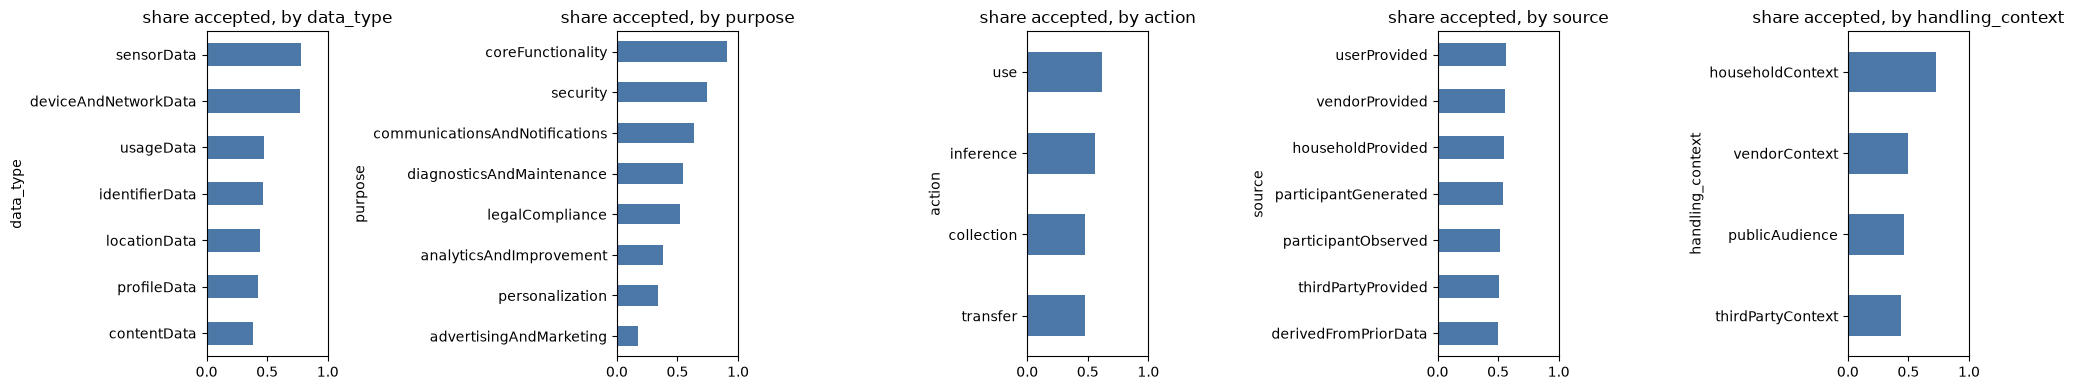

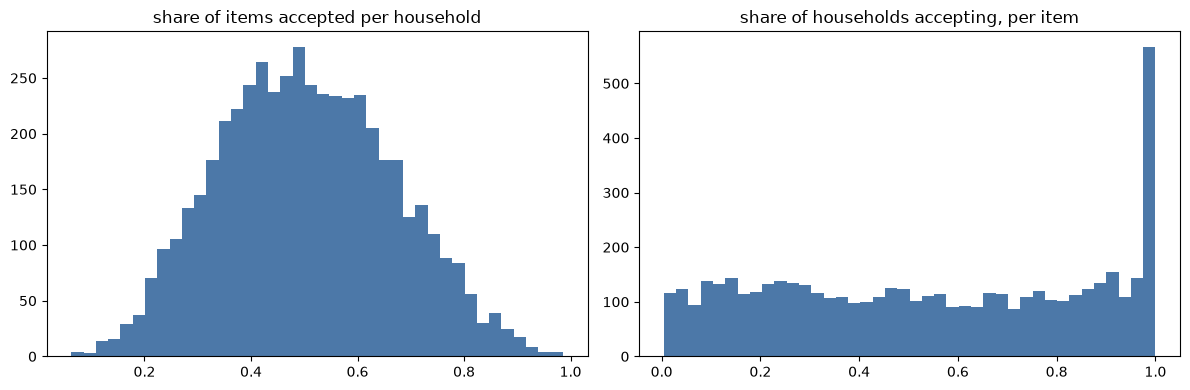

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, FIELDS):
    item_mean.groupby(items[f].map(short)).mean().sort_values().plot.barh(ax=ax, color="#4c78a8")
    ax.set_xlim(0, 1); ax.set_title(f"share accepted, by {f}")
plt.tight_layout(); plt.show()
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.hist(perm, bins=40, color="#4c78a8"); a.set_title("share of items accepted per household")
b.hist(ACCEPT[:, plausible].mean(axis=0), bins=40, color="#4c78a8"); b.set_title("share of households accepting, per item")
plt.tight_layout(); plt.show()

## Part E · Save

- `data/parameters.json` (written in Part A; committed);
- `data/households.csv` (facts, owned classes, concern, literacy, and the household's effects on the log-odds scale:
  `att_*` per purpose, `dtype_*` per data type, `ctx_*` per handling context; `vendor_trust` is the maker effect as a
  percentile), `data/answers.csv`, `data/questions.json`, `data/decisions.npy` (codes in `decision_codes.json`),
  `data/cells.csv`, `data/decisions_cells.npy` — gitignored;
- `data/sample/`: the first 200 households and their decisions on the 52 real-device items, readable — committed;
- `data/DATACARD.md`, with a SHA-256 of the decisions: same notebooks + seed ⇒ same hash.

In [22]:
for j, p in enumerate(PURPOSES):
    H[f"att_{short(p)}"] = beta_purpose[j] + E["purpose"][:, j]
for j, t in enumerate(DATA_TYPES):
    H[f"dtype_{short(t)}"] = beta_type[j] + E["data_type"][:, j]
for j, c in enumerate(HANDLING_CONTEXTS):
    H[f"ctx_{short(c)}"] = beta_context[j] + E["context"][:, j]
H["vendor_trust"] = stats.norm.cdf(Z["context"][:, 1])
H["ephemeral_gain"] = E["ephemeral"]

DATA.mkdir(exist_ok=True)
H.to_csv(DATA / "households.csv", index=False, float_format="%.4f")
A.to_csv(DATA / "answers.csv", index=False)
(DATA / "questions.json").write_text(json.dumps(QUESTIONS, indent=2) + "\n")   # texts and option order, for notebook 05
np.save(DATA / "decisions.npy", D)
(DATA / "decision_codes.json").write_text(json.dumps({str(k): v for k, v in DECISION_CODES.items()}, indent=2) + "\n")
cells.to_csv(DATA / "cells.csv", index=False)
cell_means = np.stack([V[:, cell_idx == c].mean(axis=1) for c in cells.cell_id], axis=1).astype(np.float32)
np.save(DATA / "decisions_cells.npy", cell_means)

sample = DATA / "sample"; sample.mkdir(exist_ok=True)
ids = list(range(200))
H.iloc[ids].to_csv(sample / "households.csv", index=False, float_format="%.4f")
A.iloc[ids].to_csv(sample / "answers.csv", index=False)
np.save(sample / "decisions.npy", D[ids])
real = items[items.in_corpus]
long = pd.DataFrame([(hid, i, DECISION_CODES[int(D[hid, i])]) for hid in ids for i in real.item_id],
                    columns=["household_id", "item_id", "decision"]).merge(items[["item_id", *FIELDS]], on="item_id")
long.to_csv(sample / "decisions_corpus_items.csv", index=False)

sha = hashlib.sha256(D.tobytes()).hexdigest()
shares = "\n".join(f"| `{v}` | {(D == k).mean():.1%} |" for k, v in DECISION_CODES.items())
grades = ", ".join(f"{g}: {k}" for g, k in table.grade.value_counts().sort_index().items())
(DATA / "DATACARD.md").write_text(f'''# Data card: synthetic PPD household preferences (v3)

Generated {date.today().isoformat()} by `notebooks/02_generate_households.ipynb` (seed {CONFIG['seed']}); items and device
classes from `notebooks/01_items.ipynb`. Same notebooks and seed reproduce the same data (SHA-256 below).

## What it is

{n:,} synthetic households: facts (smart devices, the device classes they own, household size, age band, children),
concern and literacy, and household effects per purpose, data type and handling context; their decision on each of the
{len(items):,} core PPD dataflows (data type x purpose x action x source x handling context, draft-dsmullen-ppd-taxonomy-05
section 6); their answers to {len(QUESTIONS)} candidate onboarding questions (concrete situations with examples), read from their own
decisions.

**This is not survey data.** Decisions are drawn from a mixed-effects logistic model whose effects come from Apthorpe et
al. 2018, Emami-Naeini et al. 2017 and Zhang et al. 2021, mapped onto PPD core terms through `references/crosswalk.csv`
and pooled in `data/parameters.json` (grades {grades}; A best, D assumed). Three numbers are calibrated: β0 = {beta0:.3f}
and the spread scale S = {S:.3f} to Emami-Naeini et al. 2017 ({share_leave:.0%} of flows leaving the home accepted; the
population's majority answer fits {maj_all:.0%} of decisions), and the decision noise τ = {TAU:.3f} to Liu et al. 2016
(redrawing a household's noise changes about 5% of its decisions). Use it to build and test the pipeline, not to claim how
real households behave.

## Files

| File | Contents |
| --- | --- |
| `parameters.json` | every effect with its value, grade and sources (committed) |
| `items.csv` | the {len(items):,} items with flags (notebook 01) |
| `corpus/device_classes.csv`, `corpus/device_fit.csv` | device classes and their fit cells (notebook 01) |
| `cells.csv` | the {N_CELLS} cells (data type x purpose x handling context) |
| `households.csv` | household_id, facts, `owns_*`, `n_classes`, concern, literacy, `att_*` / `dtype_*` / `ctx_*` (log-odds), `vendor_trust` (0..1), `ephemeral_gain` |
| `answers.csv` | household_id, one column per question |
| `decisions.npy` | uint8 [households x items]; codes in `decision_codes.json` |
| `decisions_cells.npy` | float32 [households x cells]: average acceptance (deny 0, allow-if 0.5, allow 1) per cell |
| `sample/` | the first 200 households; their decisions on the {len(real)} real-device items, readable (committed) |

## Decision shares

| Decision | Share |
| --- | --- |
{shares}

First 5 patterns (PCA) explain {', '.join(f'{x:.0%}' for x in pc)} of the variation (v2: 18%, 9%, 6%, 5%, 3%).

Decisions SHA-256: `{sha}`

## Known limits

- Grade D numbers (household spreads, three purposes, two data types, action weights, sources, boundary conditions,
  ownership shares) are our assumptions; the sensitivity notebook must vary them.
- Apthorpe's acceptability scores are converted to log-odds with one constant (KAPPA = {KAPPA}).
- The largest single pattern is general strictness ({pc[0]:.0%} of the variation); how dominant it should be is not
  measured by the studies and depends on the assumed correlations between purposes and between contexts.
- No study measures `source` or legal compliance; collection vs use is an assumed weight.
- "Ask" is never a decision (PPD effects are allow and deny); it appears only as an answer.
- One condition per item (a rule may carry several qualifiers); jurisdiction is not modelled.
- Device class is not a PPD field: it only shapes households; the household policy is the same for every device.
- Data type × purpose: the fit table and the concern types are grade D in size and shares (no study reports per-cell
  values); their direction follows A18 §5.7 and the Android profiles of Liu et al. (which differ by permission).
- Children stay in the model but are not an onboarding question (week 9): child-related data is future work.
''')
print("decisions SHA-256:", sha)

decisions SHA-256: 81aec2332e10b59ab9a8dadbe0711f5876fd2227b0b599e67f0abe1dc5b62f5d
